# Notebook 2: PCM-FM fixed-point model and RTL/HDL mapping

Companion to [Notebook 1](pcm_fm_explainer.ipynb). This notebook starts from the verified waveform and follows the integer datapath toward hardware. It runs independently. The RTL below is an architectural sketch, not a synthesized core.


## HDL implementation update

The following model discussion is followed by an implemented VHDL core: [architecture and timing](HDL.md). XSIM now passes 268280 exact I/Q/phase comparisons including stalls and reset. Its measured simulation latency is 11 clocks. Statements below about future HDL refer to the original model stage. Full Pluto integration now passes timing/DRC gates; see INTEGRATION-RESULT.md. Physical PCM-FM loopback now passes: 126975 bits, zero mismatches, 118783 held-out; see ../captures/pcm-fm-hardware-20261009-072118/RESULT.md.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pcm_fm import *
metrics, traces = validate('results')
nrz, shaped, phase, ideal, rows = traces
print(json.dumps(metrics, indent=2))

{
  "symbols": 32767,
  "samples": 262136,
  "sample_rate_hz": 2500000,
  "bit_rate": 312500.0,
  "nominal_deviation_hz": 109375.0,
  "modulation_index": 0.7,
  "fir_dc_delay_samples": 4.917587439119872,
  "coefficient_sum": 131072,
  "max_phase_error_rad": 0.0015499643388262702,
  "relative_iq_rms_error": 0.0008869697614978177,
  "max_envelope_error_counts": 0.6436030815166305,
  "shaped_peak": 1.0137229759911461,
  "increment_gain": 187904819,
  "checks": "PN period/balance; constant +/-; alternating; FIR convolution; phase wrap; random stalls; reset"
}


## 3. Replace real numbers with an explicit integer contract

| Stage | Representation / rule |
|---|---|
| NRZ history | signed 2-bit −1/+1; zero only in reset history |
| FIR coefficients | signed 18-bit integers, 17 fractional bits; asymmetric; sum exactly 131072 |
| FIR accumulator | signed 21-bit; no intermediate rounding |
| Deviation gain | 187904819, unsigned 28-bit phase units per sample at unit command |
| Multiply | signed 50-bit, then shift right 17 with nearest rounding, ties away from zero |
| Phase increment | signed 32-bit |
| Phase accumulator | unsigned 32-bit, wraps modulo 2³² |
| Sine address | upper 12 phase bits; lower bits discarded |
| I/Q | sine ROM with 4096 signed 16-bit entries, amplitude 16384; cosine uses quarter-cycle offset |

Coefficients and ROM are rounded with NumPy nearest-even during table generation. The runtime multiply has a separately specified ties-away rule. A full sine ROM is 65536 bits; eventual FPGA mapping is not yet measured.

`valid=False` freezes FIR history, phase, and output. Reset clears FIR and phase. Each valid call represents one accepted sample; an HDL pipeline may add latency, which must be tracked with valid signals. This model does not specify clock-cycle scheduling, backpressure wiring, or an achievable FPGA clock rate.

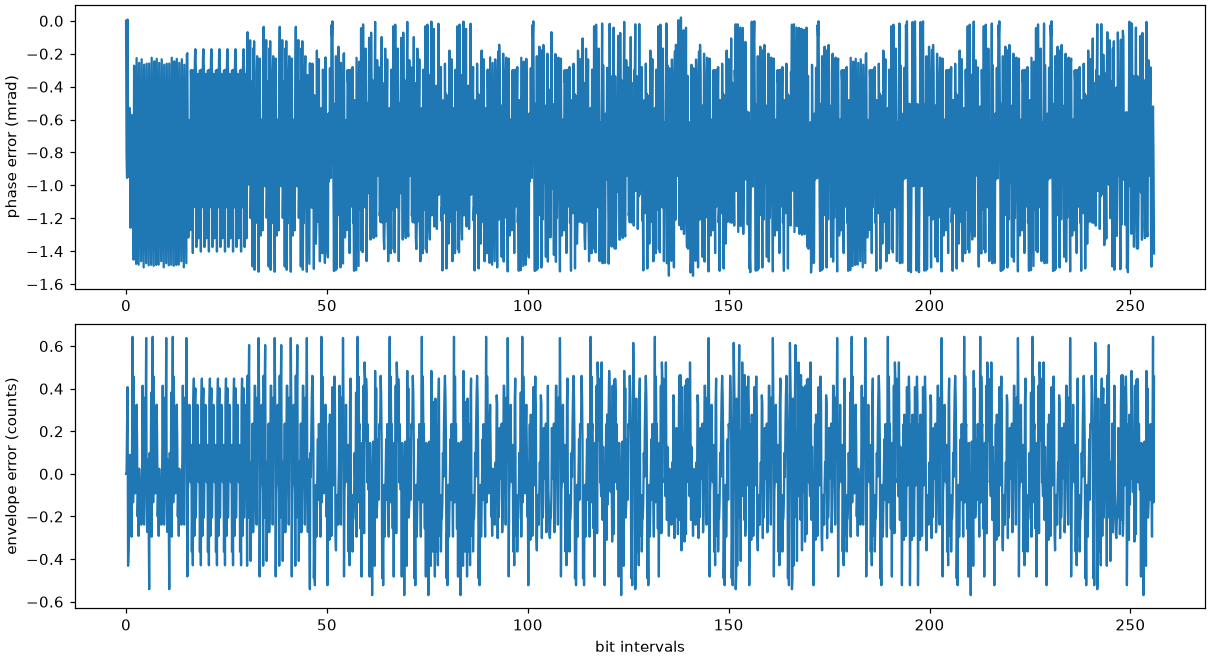

RMS I/Q error: 0.08870 %


In [2]:
actual = rows[:,3] + 1j*rows[:,4]
fig, ax = plt.subplots(2,1,figsize=(11,6),constrained_layout=True)
ax[0].plot(np.arange(2048)/SPS,np.angle(actual[:2048]*np.conj(ideal[:2048]))*1000); ax[0].set_ylabel('phase error (mrad)')
ax[1].plot(np.arange(2048)/SPS,abs(actual[:2048])-AMPLITUDE); ax[1].set_ylabel('envelope error (counts)'); ax[1].set_xlabel('bit intervals')
fig.savefig('results/integer-error.png',dpi=150)
plt.show()
print('RMS I/Q error: %.5f %%' % (100*metrics['relative_iq_rms_error']))

## 4. Evidence and handoff to HDL

The executed checks cover a full 32767-bit PN15 period, sequence balance and repetition, constant positive/negative levels, alternating bits, independent convolution versus streaming FIR, phase wrap, reset and deterministic random stalls. Comparison uses identical startup state with no phase fitting or time alignment.

`results/hdl_vectors.csv` contains 4096 accepted samples, with NRZ input, FIR sum, increment, phase and I/Q expected outputs. `coefficients_q17.txt` and `sine_lut_s16.txt` are the exact integer tables. `metrics.json` records measured errors. Run `python pcm_fm.py` to regenerate checks and vectors; run `python make_notebook.py` to regenerate this executed notebook and plots.

**Next, not implemented here:** use the frozen Bessel-derived FIR reference; schedule FIR/phase/ROM VHDL; compare HDL samples against these vectors including stalls and latency; integrate with the proven Pluto TX adapter; then use Vivado timing/resource reports and a new attenuated cable test. The previous BPSK image is untouched.

## 5. Work through one sample with exact integers

The FIR consumes the newest sample at coefficient zero. Because the input is
only −1, 0 or +1, its tap products can be coefficient negation, zero or addition;
a general multiplier per tap is unnecessary. The frequency scaling multiply is
separate. The FIR signed bound is the sum of the absolute quantized coefficients,
not merely their DC sum. Preserve headroom for transition overshoot.


In [3]:
c = quantized_coefficients()
bound = int(np.abs(c).sum())
required_bits = bound.bit_length() + 1
print('FIR worst-case magnitude:', bound, '; signed bits required:', required_bits)
assert bound < (1 << 20)
m = IntegerModulator()
print('sample   NRZ   FIR-Q17    increment    phase-U32      I      Q')
for n, x in enumerate(nrz[:12]):
    a, d, p, i, q = m.tick(int(x))
    print(f'{n:6d} {x:5d} {a:9d} {d:12d} {p:12d} {i:6d} {q:6d}')
assert round_shift(1,1) == 1 and round_shift(-1,1) == -1
assert round_shift(3,1) == 2 and round_shift(-3,1) == -2


FIR worst-case magnitude: 133424 ; signed bits required: 19
sample   NRZ   FIR-Q17    increment    phase-U32      I      Q
     0     1         0            0            0  16384      0
     1     1       384       550502       550502  16384      0
     2     1      5921      8488346      9038848  16383    201
     3     1     23686     33956250     42995098  16352   1030
     4     1     53000     75980800    118975898  16138   2826
     5     1     84968    121810125    240786023  15383   5638
     6     1    110265    158075904    398861927  13678   9019
     7     1    125036    179251609    578113536  10872  12257
     8     1    130952    187732787    765846323   7141  14746
     9     1    131970    189192192    955038515   2851  16134
    10     1    131416    188397977   1143436492  -1656  16300
    11     1    130932    187704115   1331140607  -6014  15240


## 6. Proposed HDL blocks and interfaces

```text
PN15 + samples-per-bit counter
        | signed NRZ, sample enable
        v
65-sample history -> signed coefficient add/subtract -> FIR sum
        -> deviation scaling + signed rounding
        -> modulo-2^32 phase register
        -> upper 12 bits -> sine ROM / quarter-cycle cosine
        -> signed 16-bit I/Q + output valid
        -> Pluto TX adapter (integration still pending)
```

| Proposed block | Inputs | Outputs / retained state |
|---|---|---|
| PN15 / bit hold | reset, accepted sample | NRZ; LFSR advances after 8 samples |
| shaping FIR | NRZ, sample enable | signed 21-bit sum; 65 history values |
| deviation scale | sum, valid | signed phase increment; explicit rounding |
| phase accumulator | increment, valid | unsigned wrapped phase |
| phase-to-I/Q | phase, valid | ROM-based signed 16-bit I and Q |

Proposed core ports are `clk`, `reset`, `sample_ce`, `nrz_in`,
`i_out`, `q_out`, and `out_valid`. The source counter advances only when an
input is accepted. A pipelined implementation must propagate each accepted
sample's validity; it must still drain pending outputs when no new input arrives.
The Python freeze rule describes an atomic accepted-sample model, not a rule to
freeze every stage of a future pipeline.

The exact FIR scheduling and pipeline latency remain to be chosen. A serial
adder can save logic if there are enough clocks between samples. A pipelined
adder tree can support greater throughput. Neither resource use nor timing is
established by this notebook.

### VHDL-style phase update sketch

```vhdl
-- Schematic only: inc_valid corresponds to a completed scaling operation.
if rising_edge(clk) then
  if reset = '1' then
    phase <= (others => '0');
    phase_valid <= '0';
  else
    phase_valid <= inc_valid;
    if inc_valid = '1' then
      next_phase := phase + unsigned(increment);
      phase <= next_phase;
      -- ROM address must use next_phase to match the Python convention.
      rom_addr <= next_phase(31 downto 20);
    end if;
  end if;
end if;
```

A synchronous ROM adds a cycle: delay valid to match. Converting the signed
32-bit increment to unsigned preserves its two's-complement bit pattern;
32-bit addition discards carry, giving the intended modulo wrap. Rounding of
negative scaling products must match `round_shift`, not a bare arithmetic shift.


In [4]:
# Observe accepted samples and idle clocks without changing sample order.
m = IntegerModulator()
expected = integer_model(pn15(16))
accepted = 0
print('clock  accept  sample-index  phase-state')
for clock in range(24):
    enable = clock % 3 != 1
    x = int(nrz[accepted])
    row = m.tick(x, enable)
    if enable:
        assert np.array_equal(row, expected[accepted])
    print(f'{clock:5d} {int(enable):7d} {accepted:13d} {m.phase:12d}')
    accepted += int(enable)
print('Accepted-sample ordering verified. HDL output latency remains unspecified.')


clock  accept  sample-index  phase-state
    0       1             0            0
    1       0             1            0
    2       1             1       550502
    3       1             2      9038848
    4       0             3      9038848
    5       1             3     42995098
    6       1             4    118975898
    7       0             5    118975898
    8       1             5    240786023
    9       1             6    398861927
   10       0             7    398861927
   11       1             7    578113536
   12       1             8    765846323
   13       0             9    765846323
   14       1             9    955038515
   15       1            10   1143436492
   16       0            11   1143436492
   17       1            11   1331140607
   18       1            12   1518731468
   19       0            13   1518731468
   20       1            13   1706498661
   21       1            14   1894426418
   22       0            15   1894426418
   23       1   

## 7. Testbench handoff

1. Load `results/hdl_vectors.csv`; present each NRZ value on an accepted input.
2. Queue its expected I/Q. Compare exactly when the matching `out_valid` arrives,
   rather than assuming that input and output occur on the same clock.
3. Check internal FIR, increment and phase against the corresponding columns.
4. Insert idle input cycles, reset between runs, and explicitly flush the pipeline.
5. Repeat with constant and alternating inputs and a full PN15 period.

The supplied CSV contains 4096 samples (512 bits), not the full-period test.
The Python validation executes the full period. Quantized tables are exact
inputs to the future HDL; HDL equivalence, XSIM and Vivado work are not yet done.
